# CSIS 604 Team Project — Raft Simulation

**Project:** Empirical Analysis of Raft Consensus under Network Stress

**Team Members:**
- Christian Soto
- Dan Johnson

**Course:** CSIS 604 — Distributed Systems

---



## Exercise 1 — Latency Spikes & Split-Brain Elections

### Network Latency vs. Election Frequency

#### Methodology Synthesis

To find the *precise* latency threshold that induces continuous candidate re-elections and leadership instability, it is necessary to find an observable metric via the Consul HTTP API. A naive approach involves polling the `/v1/status/leader` endpoint and noting whenever there is a change in the reported leader. However, this methodology comes with a few caveats that limit its effectiveness for tracking election events:

1. One or more election events can occur between polling attempts, reducing the signal-to-noise ratio of a leader-change count.
2. An election can result in the same node regaining leadership, leaving the leader address unchanged despite an election taking place.

Tuning the sampling interval helps mitigate (1), while (2)—along with cases where latency prevents a candidate from winning or holding quorum—motivates a stronger metric. When a cluster has no active leader, `/v1/status/leader` returns an empty value (`""`), indicating an election or leader-unavailability window at that sample timestamp.

To capture sustained instability rather than isolated swaps, we can frame leaderlessness in terms of *duty cycle*. In circuit analysis, duty cycle is the proportion of a period spent in an active state versus `0 V`. Analogously, for a leaderless duty cycle $d$ with $0 \le d \le 1$, $d$ represents the fraction of samples within an observation window where no leader is present—rising from $0$ in a stable cluster to a transition band and saturating near $1.0$ when the cluster cannot maintain leadership.

#### Guided Experiment

Run the cells below to replicate the expirement.  Note that the `docker compose` cell must be given enough time to run before moving on to the next steps

In [ ]:
# Docker Compose command to start the services defined in the docker-compose.yml file in detached mode.
# Note that we use the --wait flag to ensure that the command waits for the services!sudo docker ps to be fully started prior
# to returning control to the shell. This is useful in scenarios where subsequent commands depend on the services
# being fully operational.

!sudo docker compose -f docker-compose.yml up -d --wait

In [14]:
# Check to make sure the services are running
! sudo docker ps --format '{{{{.Names}}}} {{{{.Status}}}} --> {{{{.Ports}}}}' | grep -E 'consul([1-3]|-ui)|toxiproxy[1-3]'

Place your finger on the fingerprint reader
consul-ui Up 12 minutes --> 0.0.0.0:8500->8500/tcp, [::]:8500->8500/tcp, 8300-8302/tcp, 8301-8302/udp, 0.0.0.0:8600->8600/tcp, [::]:8600->8600/tcp, 0.0.0.0:8600->8600/udp, [::]:8600->8600/udp
toxiproxy3 Up 12 minutes --> 0.0.0.0:8476->8474/tcp, [::]:8476->8474/tcp
toxiproxy2 Up 12 minutes --> 0.0.0.0:8475->8474/tcp, [::]:8475->8474/tcp
toxiproxy1 Up 12 minutes --> 0.0.0.0:8474->8474/tcp, [::]:8474->8474/tcp
consul3-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp
consul2-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp
consul1-node Up 12 minutes --> 8300-8302/tcp, 8500/tcp, 8301-8302/udp, 8600/tcp, 8600/udp


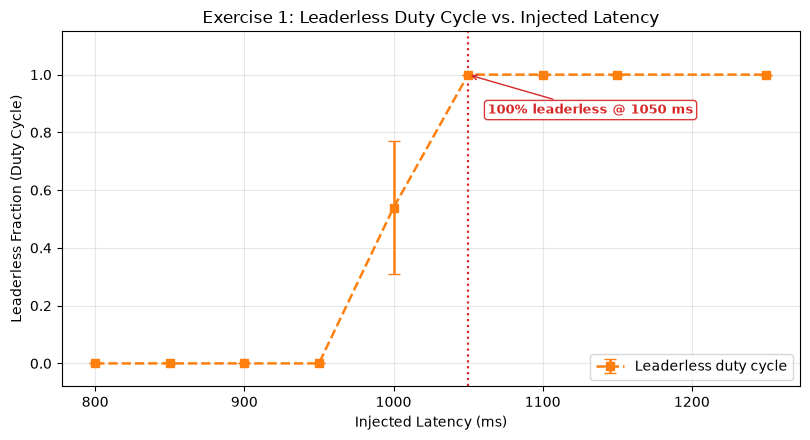

In [15]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Constants
LEADER_URL = "http://localhost:8500/v1/status/leader"
PROXIES = [
    ("http://localhost:8474", "consul1"),
    ("http://localhost:8475", "consul2"),
    ("http://localhost:8476", "consul3"),
]
TOXIC_NAME = "ex1_latency"


def set_latency_all(
    session: requests.Session, lat_ms: int, jitter_ms: int = 25
) -> None:
  """
  Set latency toxic on all proxies. Bookend this method with clear_latency_all() 
  to ensure a clean state before and after the test.
  """
  payload = {
      "name": TOXIC_NAME,
      "type": "latency",
      "attributes": {"latency": int(lat_ms), "jitter": int(jitter_ms)},
  }
  for base_url, proxy_name in PROXIES:
    resp = session.post(
        f"{base_url}/proxies/{proxy_name}/toxics",
        json=payload,
        timeout=3.0,
    )
    if resp.status_code == 409:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}", timeout=3.0
      )
      resp = session.post(
          f"{base_url}/proxies/{proxy_name}/toxics",
          json=payload,
          timeout=3.0,
      )
    resp.raise_for_status()


def clear_latency_all(session: requests.Session) -> None:
  """
  Clear latency toxic on all proxies. Bookend this method with set_latency_all()
  to ensure a clean state before and after the test.
  """
  for base_url, proxy_name in PROXIES:
    try:
      session.delete(
          f"{base_url}/proxies/{proxy_name}/toxics/{TOXIC_NAME}",
          timeout=3.0,
      )
    except requests.RequestException:
      pass


def measure_leaderless_duty_cycle(
    session: requests.Session,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    timeout: float = 1.0,
) -> dict:
  """
  Measure the fraction of time the cluster is leaderless over a given window.
  Output is a dictionary with the following shape:
  {
      "elapsed_s": float,  # Total elapsed time in seconds}
      "n_samples": int,  # Total number of samples taken
      "leaderless_ratio": float,  # Fraction of samples where no leader was found
  }
  """
  leaderless_samples = 0
  total_samples = 0
  t0 = time.monotonic()
  deadline = t0 + window_s

  while time.monotonic() < deadline:
    leader = ""
    try:
      r = session.get(LEADER_URL, timeout=timeout)
      if r.ok:
        leader = r.text.strip().strip('"')
    except requests.RequestException:
      leader = ""

    total_samples += 1
    if not leader:
      leaderless_samples += 1

    rem = deadline - time.monotonic()
    if rem > 0:
      time.sleep(min(interval_s, rem))

  elapsed = max(time.monotonic() - t0, 1e-6)
  return {
      "elapsed_s": elapsed,
      "n_samples": total_samples,
      "leaderless_ratio": leaderless_samples / max(total_samples, 1),
  }


def run_precision_duty_cycle(
    latencies_ms: list[int],
    reps: int = 3,
    window_s: float = 12.0,
    interval_s: float = 0.2,
    jitter_ms: int = 25,
    settle_s: float = 2.0,
    csv_path: str = "ex1_leaderless_duty_cycle.csv",
    plot_path: str = "ex1_leaderless_duty_cycle.png",
) -> pd.DataFrame:
  """
  Run a precision duty cycle experiment by injecting latency into the cluster and
  measuring the fraction of time the cluster is leaderless. The results are saved
  to a CSV file and a plot is generated. The function returns a DataFrame containing
  the raw results of the experiment. 
  """
  rows: list[dict] = []
  with requests.Session() as session:
    clear_latency_all(session)
    try:
      for lat in latencies_ms:
        for rep in range(reps):
          if lat > 0:
            set_latency_all(session, lat_ms=lat, jitter_ms=jitter_ms)
          try:
            stats = measure_leaderless_duty_cycle(
                session, window_s=window_s, interval_s=interval_s
            )
            rows.append({
                "latency_ms": lat,
                "jitter_ms": jitter_ms if lat > 0 else 0,
                "rep": rep,
                **stats,
            })
          finally:
            if lat > 0:
              clear_latency_all(session)
          if settle_s > 0:
            time.sleep(settle_s)
    finally:
      clear_latency_all(session)

  df = pd.DataFrame(rows)
  df.to_csv(csv_path, index=False)

  summary = (
      df.groupby("latency_ms", as_index=False)
      .agg(
          mean_leaderless=("leaderless_ratio", "mean"),
          std_leaderless=("leaderless_ratio", "std"),
      )
      .fillna({"std_leaderless": 0.0})
  )

  fig, ax = plt.subplots(figsize=(8.2, 4.5))
  ax.errorbar(
      summary["latency_ms"],
      summary["mean_leaderless"],
      yerr=summary["std_leaderless"],
      marker="s",
      linestyle="--",
      capsize=4,
      color="tab:orange",
      linewidth=1.8,
      label="Leaderless duty cycle",
  )

  ax.set_title("Exercise 1: Leaderless Duty Cycle vs. Injected Latency")
  ax.set_xlabel("Injected Latency (ms)")
  ax.set_ylabel("Leaderless Fraction (Duty Cycle)")
  ax.set_ylim(-0.08, 1.15)
  ax.grid(True, alpha=0.3)

  sat_rows = summary[summary["mean_leaderless"] >= 0.99]
  if not sat_rows.empty:
    sat_lat = sat_rows.iloc[0]["latency_ms"]
    sat_val = sat_rows.iloc[0]["mean_leaderless"]
    ax.axvline(sat_lat, color="tab:red", linestyle=":", linewidth=1.6)
    ax.annotate(
        f"100% leaderless @ {sat_lat:g} ms",
        xy=(sat_lat, sat_val),
        xytext=(14, -28),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="->", color="tab:red"),
        fontsize=9,
        fontweight="bold",
        color="tab:red",
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="white",
            ec="tab:red",
            alpha=0.92,
        ),
    )

  ax.legend(loc="lower right")
  fig.tight_layout()
  plt.savefig(plot_path, dpi=150)
  plt.show()

  return df


precision_latencies = [800, 850, 900, 950, 1000, 1050, 1100, 1150, 1250]
df_ex1 = run_precision_duty_cycle(
    precision_latencies,
    reps=3,
    window_s=12.0,
    interval_s=0.2,
    jitter_ms=25,
    settle_s=2.0,
)

### Exercise 1 — Analysis

**PLACEHOLDER**


---

## Exercise 2 — Minority Partition & Uncommitted Log Tracing

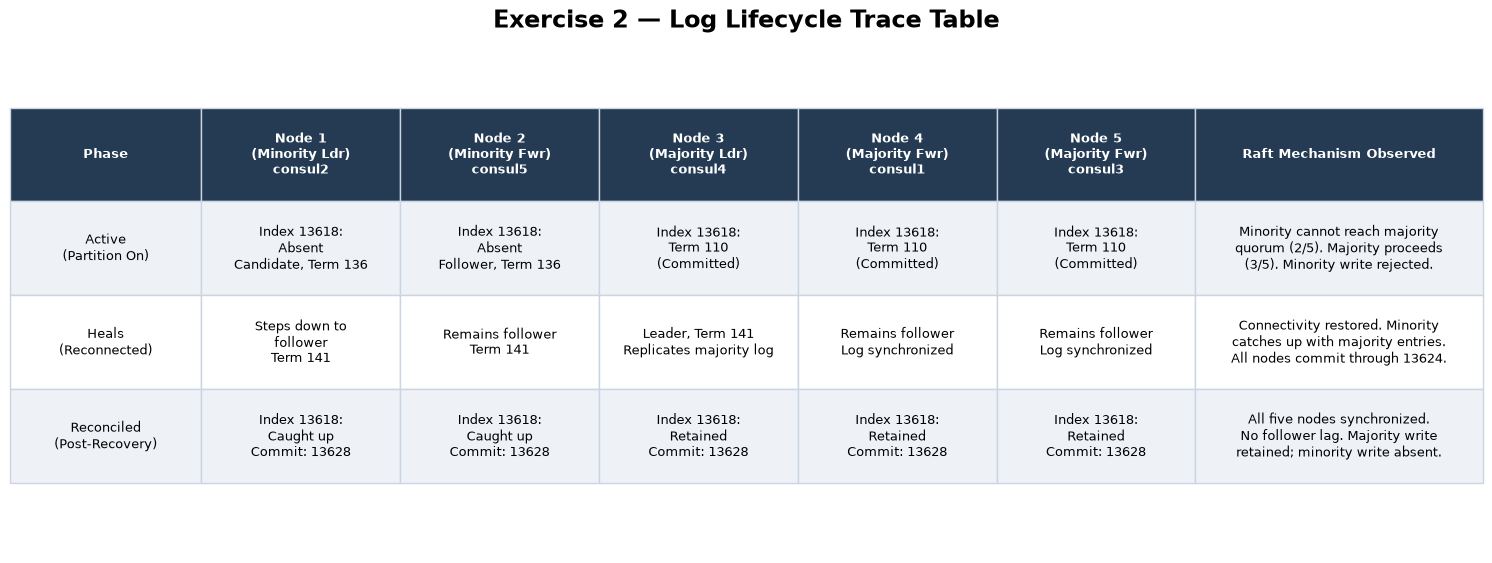

In [14]:
import matplotlib.pyplot as plt

columns = [
    "Phase",
    "Node 1\n(Minority Ldr)\nconsul2",
    "Node 2\n(Minority Fwr)\nconsul5",
    "Node 3\n(Majority Ldr)\nconsul4",
    "Node 4\n(Majority Fwr)\nconsul1",
    "Node 5\n(Majority Fwr)\nconsul3",
    "Raft Mechanism Observed"
]

rows = [
    [
        "Active\n(Partition On)",
        "Index 13618:\nAbsent\nCandidate, Term 136",
        "Index 13618:\nAbsent\nFollower, Term 136",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Index 13618:\nTerm 110\n(Committed)",
        "Minority cannot reach majority\n"
        "quorum (2/5). Majority proceeds\n"
        "(3/5). Minority write rejected."
    ],
    [
        "Heals\n(Reconnected)",
        "Steps down to\nfollower\nTerm 141",
        "Remains follower\nTerm 141",
        "Leader, Term 141\nReplicates majority log",
        "Remains follower\nLog synchronized",
        "Remains follower\nLog synchronized",
        "Connectivity restored. Minority\n"
        "catches up with majority entries.\n"
        "All nodes commit through 13624."
    ],
    [
        "Reconciled\n(Post-Recovery)",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nCaught up\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "Index 13618:\nRetained\nCommit: 13628",
        "All five nodes synchronized.\n"
        "No follower lag. Majority write\n"
        "retained; minority write absent."
    ]
]

fig, ax = plt.subplots(figsize=(19, 6.5))
ax.axis("off")

ax.set_title(
    "Exercise 2 — Log Lifecycle Trace Table",
    fontsize=17, fontweight="bold", pad=18
)

table = ax.table(
    cellText=rows,
    colLabels=columns,
    colWidths=[0.13, 0.135, 0.135, 0.135, 0.135, 0.135, 0.195],
    cellLoc="center",
    loc="center",
    bbox=[0, 0.14, 1, 0.75]
)

table.auto_set_font_size(False)
table.set_fontsize(9)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#CBD5E1")
    if r == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor("#EEF2F7" if r % 2 else "white")
        cell.set_text_props(va="center")

plt.show()

### Exercise 2 — Analysis

The five-node Consul cluster was divided into a three-node majority (`consul1`, `consul3`, and `consul4`) and a two-node minority (`consul2` and `consul5`). The partition separated the original leader, `consul2`, from the majority. KV writes were attempted on both sides to observe how Raft handles the loss of a majority quorum.

**Active (Partition On):** The majority elected `consul4` as its new leader and committed entries through log index 13618 with term 110. The minority remained at index 13586 with its last log term at 107. `consul2` entered candidate state because it could no longer maintain leadership without a majority quorum. The majority write succeeded while the minority write returned "No cluster leader."

**Heals (Reconnected):** Network communication was restored and the minority nodes rejoined the cluster as followers. All five nodes reached log and commit index 13624 with term 141. This showed that the minority had caught up with the entries committed by the majority during the partition.

**Reconciled (Post-Recovery):** All five nodes eventually reached commit index 13628 with no replication lag. `consul2` regained leadership and the majority write remained available. The minority write was not committed.

Log index 13618 was used to trace the difference between the two groups. The majority committed this entry while the minority was unable to make progress. Raft synchronized the logs after connectivity was restored. The experiment demonstrated log recovery through replication rather than the replacement of a conflicting uncommitted entry, which was not observed.

---

## Exercise 3 — Packet Loss & Throughput Degradation

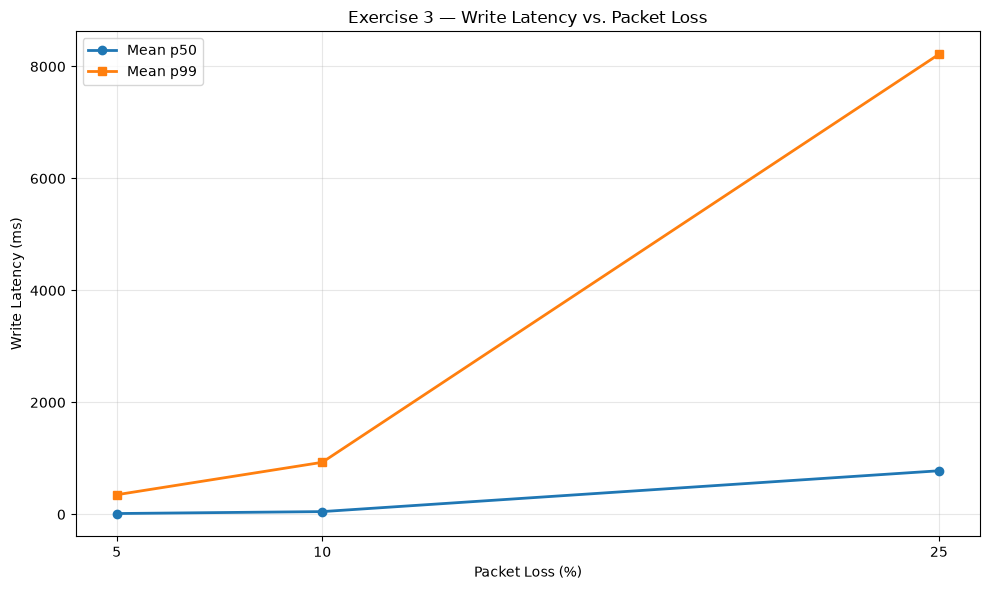

In [15]:
import matplotlib.pyplot as plt
import numpy as np

loss = np.array([5, 10, 25])

p50 = np.array([
    [14.10, 14.70, 15.82],
    [41.59, 62.42, 44.48],
    [972.78, 695.10, 668.10]
])

p99 = np.array([
    [267.62, 504.47, 279.79],
    [652.40, 1369.59, 768.05],
    [5650.17, 9742.00, 9260.92]
])

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    loss, p50.mean(axis=1),
    marker="o", linewidth=2,
    label="Mean p50"
)

ax.plot(
    loss, p99.mean(axis=1),
    marker="s", linewidth=2,
    label="Mean p99"
)

ax.set_title("Exercise 3 — Write Latency vs. Packet Loss")
ax.set_xlabel("Packet Loss (%)")
ax.set_ylabel("Write Latency (ms)")
ax.set_xticks(loss)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### Exercise 3 — Analysis

The results show that increasing packet loss significantly affected write latency. Average p50 latency increased from 14.87 ms at 5% packet loss to 778.66 ms at 25%, while average p99 increased from 350.63 ms to 8217.70 ms.

The difference occurs because p50 represents the median write request, while p99 represents requests experiencing the longest delays. Packet loss does not affect every request equally. Affected requests experience TCP retransmissions, repeated packet loss, or delays waiting for Raft replication to reach a majority quorum. These delays accumulate for the slowest requests, causing p99 to increase much more sharply in absolute latency than p50.

At 25% packet loss, 431 of 3000 write attempts failed, primarily due to timeouts. These failures were excluded from the latency percentiles because their successful completion times could not be measured. Consequently, the reported p99 represents only successful writes and may understate the overall impact of packet loss.

The experiment demonstrates that Raft can continue processing writes under significant packet loss, but its tail latency and write reliability deteriorate as network conditions worsen.